# Heathrow Passenger Analysis and Forecasting
## 02 — Passenger Trends and Forecast Evaluation

### Purpose
Explore monthly passenger demand and seasonality, then evaluate
a simple forecast against held-out historical observations.

### Scope
- Reported monthly traffic: October 2024–September 2026.
- Examine passenger trends and market mix.
- Compare forecasts with a seasonal naïve benchmark.
- Distinguish historical actuals from forecast outputs.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

traffic_monthly = pd.read_csv(
    PROJECT_ROOT / "data" / "processed" / "heathrow_traffic_monthly.csv",
    parse_dates=["month"]
).sort_values("month").reset_index(drop=True)

print("Rows:", len(traffic_monthly))
traffic_monthly.head()

Rows: 24


,month,passengers,air_transport_movements,cargo_tonnes
0,2024-10-01,7214853,40980,140598.578
1,2024-11-01,6500620,38084,139204.437
2,2024-12-01,7074890,38854,132616.508
3,2025-01-01,6319076,38699,119329.942
4,2025-02-01,5709458,35806,120765.418


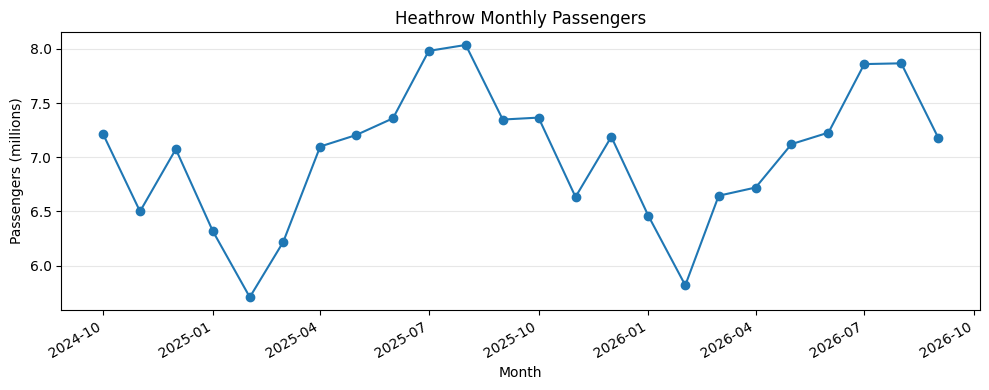

In [2]:
fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(
    traffic_monthly["month"],
    traffic_monthly["passengers"] / 1_000_000,
    marker="o"
)

ax.set_title("Heathrow Monthly Passengers")
ax.set_xlabel("Month")
ax.set_ylabel("Passengers (millions)")
ax.grid(axis="y", alpha=0.3)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

In [3]:
peak = traffic_monthly.loc[traffic_monthly["passengers"].idxmax()]
low = traffic_monthly.loc[traffic_monthly["passengers"].idxmin()]

print("Highest:", peak["month"].strftime("%B %Y"),
      f'— {peak["passengers"]:,} passengers')

print("Lowest:", low["month"].strftime("%B %Y"),
      f'— {low["passengers"]:,} passengers')

Highest: August 2025 — 8,035,996 passengers
Lowest: February 2025 — 5,709,458 passengers


In [4]:
traffic_monthly["days_in_month"] = (
    traffic_monthly["month"].dt.days_in_month
)

traffic_monthly["passengers_per_day"] = (
    traffic_monthly["passengers"]
    / traffic_monthly["days_in_month"]
)

traffic_monthly[
    ["month", "passengers", "days_in_month", "passengers_per_day"]
].round({"passengers_per_day": 0})

,month,passengers,days_in_month,passengers_per_day
0,2024-10-01,7214853,31,232737.0
1,2024-11-01,6500620,30,216687.0
2,2024-12-01,7074890,31,228222.0
3,2025-01-01,6319076,31,203841.0
4,2025-02-01,5709458,28,203909.0
5,2025-03-01,6218374,31,200593.0
6,2025-04-01,7098983,30,236633.0
7,2025-05-01,7204388,31,232400.0
8,2025-06-01,7359252,30,245308.0
9,2025-07-01,7981137,31,257456.0


In [5]:
traffic_monthly["passengers_yoy_pct"] = (
    traffic_monthly["passengers"]
    .pct_change(periods=12, fill_method=None)
    * 100
)

traffic_monthly[
    ["month", "passengers", "passengers_yoy_pct"]
].tail(12).round({"passengers_yoy_pct": 2})

,month,passengers,passengers_yoy_pct
12,2025-10-01,7365772,2.09
13,2025-11-01,6634019,2.05
14,2025-12-01,7188658,1.61
15,2026-01-01,6460877,2.24
16,2026-02-01,5819080,1.92
17,2026-03-01,6645184,6.86
18,2026-04-01,6721032,-5.32
19,2026-05-01,7121212,-1.15
20,2026-06-01,7227494,-1.79
21,2026-07-01,7859408,-1.53


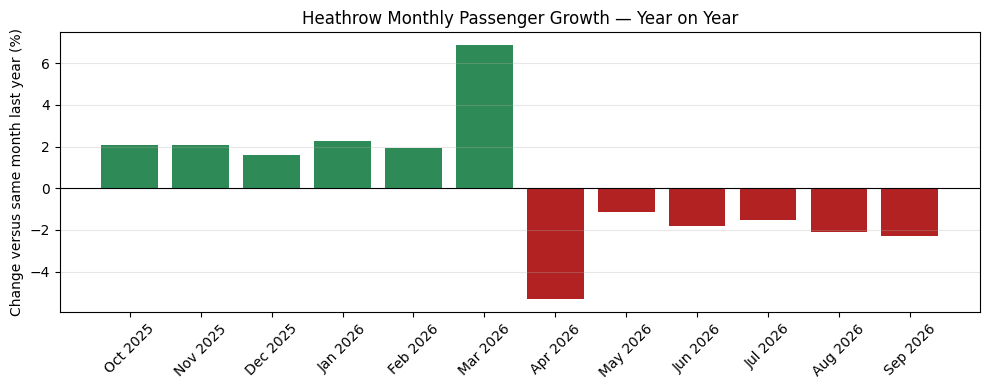

In [6]:
growth = traffic_monthly.dropna(subset=["passengers_yoy_pct"])

colours = [
    "seagreen" if value >= 0 else "firebrick"
    for value in growth["passengers_yoy_pct"]
]

fig, ax = plt.subplots(figsize=(10, 4))

ax.bar(
    growth["month"].dt.strftime("%b %Y"),
    growth["passengers_yoy_pct"],
    color=colours
)

ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Heathrow Monthly Passenger Growth — Year on Year")
ax.set_ylabel("Change versus same month last year (%)")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### Initial passenger-analysis findings

- Period analysed: October 2024–September 2026 (24 months).
- Highest monthly total: August 2025 — 8,035,996 passengers.
- Lowest monthly total: February 2025 — 5,709,458 passengers.
- Both years show summer peaks and lower winter volumes,
  suggesting annual seasonality.
- Month length affects totals: March 2025 had fewer passengers
  per day than February 2025.
- Year-on-year passenger growth was positive from October 2025
  to March 2026, then negative from April to September 2026.
- These patterns describe the data; they do not establish causes.
- Two years of observations provide limited evidence for forecasting.

In [7]:
train = traffic_monthly.iloc[:18].copy()
test = traffic_monthly.iloc[18:].copy()

print(
    "Training:", train["month"].min().strftime("%b %Y"),
    "to", train["month"].max().strftime("%b %Y"),
    f"({len(train)} months)"
)

print(
    "Testing:", test["month"].min().strftime("%b %Y"),
    "to", test["month"].max().strftime("%b %Y"),
    f"({len(test)} months)"
)

Training: Oct 2024 to Mar 2026 (18 months)
Testing: Apr 2026 to Sep 2026 (6 months)


In [8]:
forecast_evaluation = test[["month", "passengers"]].rename(
    columns={"passengers": "actual_passengers"}
).copy()

prior_year_months = (
    forecast_evaluation["month"] - pd.DateOffset(years=1)
)

forecast_evaluation["seasonal_naive_forecast"] = (
    train.set_index("month")["passengers"]
    .reindex(prior_year_months)
    .to_numpy()
)

forecast_evaluation

,month,actual_passengers,seasonal_naive_forecast
18,2026-04-01,6721032,7098983
19,2026-05-01,7121212,7204388
20,2026-06-01,7227494,7359252
21,2026-07-01,7859408,7981137
22,2026-08-01,7866510,8035996
23,2026-09-01,7179707,7347948


In [9]:
forecast_evaluation["error_passengers"] = (
    forecast_evaluation["actual_passengers"]
    - forecast_evaluation["seasonal_naive_forecast"]
)

forecast_evaluation["error_pct"] = (
    forecast_evaluation["error_passengers"]
    / forecast_evaluation["actual_passengers"]
    * 100
)

forecast_evaluation.round({"error_pct": 2})

,month,actual_passengers,seasonal_naive_forecast,error_passengers,error_pct
18,2026-04-01,6721032,7098983,-377951,-5.62
19,2026-05-01,7121212,7204388,-83176,-1.17
20,2026-06-01,7227494,7359252,-131758,-1.82
21,2026-07-01,7859408,7981137,-121729,-1.55
22,2026-08-01,7866510,8035996,-169486,-2.15
23,2026-09-01,7179707,7347948,-168241,-2.34


In [10]:
mae = forecast_evaluation["error_passengers"].abs().mean()

rmse = (
    forecast_evaluation["error_passengers"].pow(2).mean()
) ** 0.5

mape = forecast_evaluation["error_pct"].abs().mean()

print(f"MAE: {mae:,.0f} passengers")
print(f"RMSE: {rmse:,.0f} passengers")
print(f"MAPE: {mape:.2f}%")

MAE: 175,390 passengers
RMSE: 199,572 passengers
MAPE: 2.44%


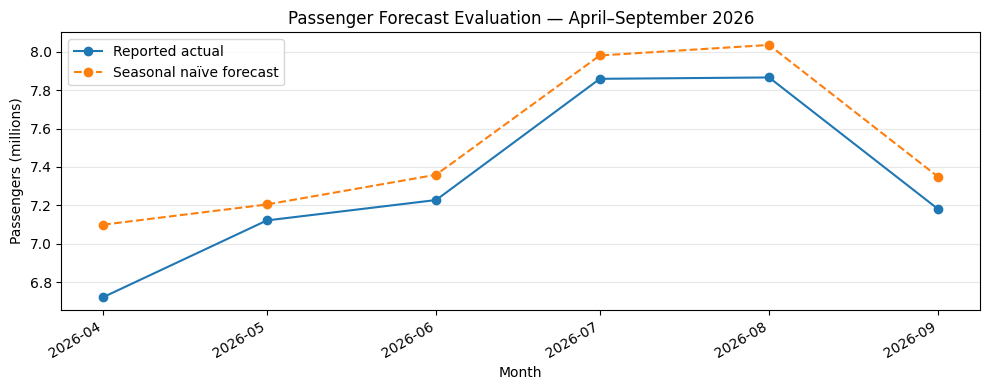

In [11]:
fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(
    forecast_evaluation["month"],
    forecast_evaluation["actual_passengers"] / 1_000_000,
    marker="o",
    label="Reported actual"
)

ax.plot(
    forecast_evaluation["month"],
    forecast_evaluation["seasonal_naive_forecast"] / 1_000_000,
    marker="o",
    linestyle="--",
    label="Seasonal naïve forecast"
)

ax.set_title("Passenger Forecast Evaluation — April–September 2026")
ax.set_ylabel("Passengers (millions)")
ax.set_xlabel("Month")
ax.legend()
ax.grid(axis="y", alpha=0.3)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

### Seasonal naïve forecast evaluation

- Training period: October 2024–March 2026 (18 months).
- Test period: April–September 2026 (6 months).
- Method: forecast each month using the same month one year earlier.
- MAE: 175,390 passengers.
- RMSE: 199,572 passengers.
- MAPE: 2.44%.
- The forecast captures the summer peak but overestimates all six test months.
- April has the largest absolute error: 377,951 passengers.
- Results cover one six-month holdout and may not generalise to other periods.

In [12]:
last_observed_passengers = train.iloc[-1]["passengers"]

forecast_evaluation["naive_forecast"] = last_observed_passengers

forecast_evaluation[
    [
        "month",
        "actual_passengers",
        "seasonal_naive_forecast",
        "naive_forecast"
    ]
]

,month,actual_passengers,seasonal_naive_forecast,naive_forecast
18,2026-04-01,6721032,7098983,6645184
19,2026-05-01,7121212,7204388,6645184
20,2026-06-01,7227494,7359252,6645184
21,2026-07-01,7859408,7981137,6645184
22,2026-08-01,7866510,8035996,6645184
23,2026-09-01,7179707,7347948,6645184


In [13]:
comparison_rows = []

for model in ["naive_forecast", "seasonal_naive_forecast"]:
    errors = (
        forecast_evaluation["actual_passengers"]
        - forecast_evaluation[model]
    )

    comparison_rows.append({
        "model": model,
        "mae_passengers": errors.abs().mean(),
        "rmse_passengers": (errors.pow(2).mean()) ** 0.5,
        "mape_pct": (
            errors.abs()
            / forecast_evaluation["actual_passengers"]
        ).mean() * 100
    })

model_comparison = pd.DataFrame(comparison_rows)

model_comparison.round(2)

,model,mae_passengers,rmse_passengers,mape_pct
0,naive_forecast,684043.17,798241.03,9.05
1,seasonal_naive_forecast,175390.17,199571.99,2.44


In [14]:
model_comparison.to_csv(
    PROJECT_ROOT / "data" / "processed"
    / "heathrow_forecast_model_comparison.csv",
    index=False
)

forecast_evaluation.to_csv(
    PROJECT_ROOT / "data" / "processed"
    / "heathrow_passenger_forecast_evaluation.csv",
    index=False,
    date_format="%Y-%m-%d"
)

print("Saved model comparison and forecast evaluation.")

Saved model comparison and forecast evaluation.


### First-version forecast method

Two methods were evaluated on April–September 2026:

| Method | MAE (passengers) | RMSE (passengers) | MAPE |
|---|---:|---:|---:|
| Naïve | 684,043 | 798,241 | 9.05% |
| Seasonal naïve | 175,390 | 199,572 | 2.44% |

Seasonal naïve is selected for the first version because it performed
better on all three measures and preserves the annual seasonal pattern.

It assumes each future month repeats the same month one year earlier.
It does not explicitly model growth, capacity changes or external events.

The six-month holdout informed model selection, so these results are
not an independent assessment of the selected model's future accuracy.

In [15]:
forecast_months = pd.date_range(
    start="2026-10-01",
    end="2026-12-01",
    freq="MS"
)

passenger_forecast = pd.DataFrame({"month": forecast_months})

passenger_forecast["forecast_passengers"] = (
    traffic_monthly.set_index("month")["passengers"]
    .reindex(forecast_months - pd.DateOffset(years=1))
    .to_numpy()
)

passenger_forecast["data_status"] = "model_forecast"
passenger_forecast["forecast_method"] = "seasonal_naive"
passenger_forecast["forecast_as_of"] = "2026-09-30"

passenger_forecast

,month,forecast_passengers,data_status,forecast_method,forecast_as_of
0,2026-10-01,7365772,model_forecast,seasonal_naive,2026-09-30
1,2026-11-01,6634019,model_forecast,seasonal_naive,2026-09-30
2,2026-12-01,7188658,model_forecast,seasonal_naive,2026-09-30


In [16]:
actual_2026 = traffic_monthly.loc[
    traffic_monthly["month"].dt.year == 2026,
    "passengers"
].sum()

forecast_remaining_2026 = (
    passenger_forecast["forecast_passengers"].sum()
)

full_year_passenger_outlook = actual_2026 + forecast_remaining_2026

print(f"Jan–Sep reported actual: {actual_2026:,.0f}")
print(f"Oct–Dec model forecast: {forecast_remaining_2026:,.0f}")
print(f"2026 full-year outlook: {full_year_passenger_outlook:,.0f}")

Jan–Sep reported actual: 62,900,504
Oct–Dec model forecast: 21,188,449
2026 full-year outlook: 84,088,953


In [17]:
passengers_2025 = traffic_monthly.loc[
    traffic_monthly["month"].dt.year == 2025,
    "passengers"
].sum()

outlook_change = full_year_passenger_outlook - passengers_2025
outlook_change_pct = outlook_change / passengers_2025 * 100

print(f"2025 reported passengers: {passengers_2025:,.0f}")
print(f"2026 passenger outlook: {full_year_passenger_outlook:,.0f}")
print(f"Change: {outlook_change:,.0f} passengers")
print(f"Change (%): {outlook_change_pct:.2f}%")

2025 reported passengers: 84,463,061
2026 passenger outlook: 84,088,953
Change: -374,108 passengers
Change (%): -0.44%


In [18]:
passenger_forecast.to_csv(
    PROJECT_ROOT / "data" / "processed"
    / "heathrow_passenger_forecast_2026_q4.csv",
    index=False,
    date_format="%Y-%m-%d"
)

print("Saved: heathrow_passenger_forecast_2026_q4.csv")

Saved: heathrow_passenger_forecast_2026_q4.csv


### 2026 full-year passenger outlook

| Component | Passengers |
|---|---:|
| January–September reported actual | 62,900,504 |
| October–December model forecast | 21,188,449 |
| Full-year outlook | 84,088,953 |

The outlook is 374,108 passengers below 2025, a decrease of 0.44%.

The forecast uses data through September 2026 and assumes that
October–December repeats the corresponding 2025 passenger totals.

This is our modelled outlook, not Heathrow's published forecast.